# OSMnx-demo: Kristiansand

Fem ting vi gjør med gatenettverket fra OpenStreetMap:

1. **Eget nettverk med basisvekter**: lengde og reisetid for bil, sykkel og gange
2. **Nettverk med «mine preferanser»**: egen kostnadsfunksjon for sykkel
3. **A-til-B-ruter**: korteste, raskeste og foretrukne rute
4. **Flerstopps-analyse**: beste rekkefølge for en rundtur med flere stopp
5. **Isokroner**: hva rekker du på 5, 10 og 15 minutter til fots, på sykkel og i bil?

Til slutt tre ekstra analyser: tilgjengelighet til kafé, edge betweenness og gateorientering.

Alt hentes live fra OSM (Overpass/Nominatim) og caches lokalt i `cache/` og `data/`,
så første kjøring tar noen minutter og senere kjøringer går fort.

In [1]:
import time
from itertools import permutations
from pathlib import Path

import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd

ox.settings.use_cache = True
ox.settings.cache_folder = "cache"
ox.settings.log_console = False

DATA = Path("data")
KART = Path("kart")
DATA.mkdir(exist_ok=True)
KART.mkdir(exist_ok=True)

# Okabe-Ito: fargeblindsikre kategorifarger
BLÅ, ORANSJE, GRØNN, ROSA = "#0072B2", "#D55E00", "#009E73", "#CC79A7"
print("osmnx", ox.__version__)

osmnx 2.1.1


## 0. Steder

Vi geokoder noen kjente punkter i Kristiansand med Nominatim.

In [2]:
STEDER = {
    "Kristiansand stasjon": "Kristiansand stasjon, Norway",
    "Fiskebrygga": "Fiskebrygga, Kristiansand, Norway",
    "Domkirken": "Kristiansand domkirke, Norway",
    "Odderøya": "Odderøya, Kristiansand, Norway",
    "Baneheia": "Baneheia, Kristiansand, Norway",
    "UiA Gimlemoen": "Universitetet i Agder, Kristiansand, Norway",
}
KOORD = {navn: ox.geocode(q) for navn, q in STEDER.items()}  # (lat, lon)
pd.DataFrame(KOORD, index=["lat", "lon"]).T

,lat,lon
Kristiansand stasjon,58.145604,7.988187
Fiskebrygga,58.140845,7.995103
Domkirken,58.146113,7.994615
Odderøya,58.135798,8.002974
Baneheia,58.153579,7.984191
UiA Gimlemoen,58.163098,8.001443


In [3]:
SENTRUM = KOORD["Kristiansand stasjon"]


def lag_kart(senter=SENTRUM, zoom=14):
    return folium.Map(location=senter, zoom_start=zoom, tiles="OpenStreetMap")


def legg_til_steder(m, navn=None):
    for n in navn or KOORD:
        folium.Marker(KOORD[n], tooltip=n, icon=folium.Icon(color="gray", icon="info-sign")).add_to(m)

## 1. Eget nettverk med basisvekter

`graph_from_point` laster ned alle gater innenfor en avstand fra et punkt.
Vi lager tre nettverk, ett for hver transportmåte. Grafen er en NetworkX `MultiDiGraph`:
noder er kryss, kanter er gatestrekninger, og kantene har attributter (`length`, `highway`, ...).

**Basisvektene** er det som ligger i kantene som utgangspunkt:
- `length` (meter) kommer rett fra OSM-geometrien
- `travel_time` (sekunder) beregner vi selv ut fra fart

In [4]:
def med_retry(f, *args, forsøk=6, **kwargs):
    """Den offentlige Overpass-serveren er ofte overbelastet (502), så vi prøver igjen med økende ventetid."""
    for i in range(forsøk):
        try:
            return f(*args, **kwargs)
        except Exception as feil:
            if i == forsøk - 1:
                raise
            ventetid = 15 * 2**i
            print(f"Feilet ({str(feil)[:60]}...), prøver igjen om {ventetid} s")
            time.sleep(ventetid)


def hent_nett(navn, nettverkstype, dist, senter=SENTRUM):
    """Last ned (eller les fra disk) et nettverk rundt `senter`."""
    fil = DATA / f"{navn}.graphml"
    if fil.exists():
        return ox.load_graphml(fil)
    G = med_retry(ox.graph_from_point, senter, dist=dist, network_type=nettverkstype)
    ox.save_graphml(G, fil)
    return G


G_bil = hent_nett("bil", "drive", dist=8000)
G_sykkel = hent_nett("sykkel", "bike", dist=5000)
G_gange = hent_nett("gange", "walk", dist=2500)

### Basisvekter: reisetid

- **Bil**: OSMnx leser `maxspeed` og fyller inn manglende verdier med snitt per veitype.
- **Sykkel og gange**: vi setter en konstant fart (15 og 4,8 km/t).

In [5]:
def sett_konstant_fart(G, kmh):
    for _, _, d in G.edges(data=True):
        d["speed_kph"] = kmh
        d["travel_time"] = d["length"] / (kmh / 3.6)
    return G


G_bil = ox.routing.add_edge_speeds(G_bil)
G_bil = ox.routing.add_edge_travel_times(G_bil)
G_sykkel = sett_konstant_fart(G_sykkel, 15)
G_gange = sett_konstant_fart(G_gange, 4.8)

In [6]:
rader = []
for navn, G in [("bil", G_bil), ("sykkel", G_sykkel), ("gange", G_gange)]:
    s = ox.stats.basic_stats(G)
    rader.append(
        {
            "nett": navn,
            "kryss (noder)": s["n"],
            "gatestrekninger (kanter)": s["m"],
            "km vei totalt": round(s["edge_length_total"] / 1000),
            "snitt kryss pr. node": round(s["k_avg"], 2),
        }
    )
pd.DataFrame(rader).set_index("nett")

,kryss (noder),gatestrekninger (kanter),km vei totalt,snitt kryss pr. node
nett,,,,
bil,3867,8319,1151,4.30
sykkel,10294,24779,1881,4.81
gange,3722,9512,501,5.11


In [7]:
nodes, edges = ox.graph_to_gdfs(G_bil)
edges[["name", "highway", "maxspeed", "speed_kph", "length", "travel_time"]].head()

name     highway  maxspeed  speed_kph  \
u        v          key                                                 
26598211 461283730  0            NaN    motorway  [90, 80]       85.0   
26598222 936605326  0            NaN  trunk_link        80       80.0   
         520477758  0            NaN       trunk        80       80.0   
26598271 1171919210 0    Vesterveien       trunk        60       60.0   
26600059 461087690  0            NaN       trunk        50       50.0   

                              length  travel_time  
u        v          key                            
26598211 461283730  0    1247.244036    52.824453  
26598222 936605326  0     257.041001    11.566845  
         520477758  0     259.085906    11.658866  
26598271 1171919210 0     577.984963    34.679098  
26600059 461087690  0      18.744145     1.349578

In [8]:
# Eksporter til GeoPackage så nettverket kan åpnes i QGIS
ox.save_graph_geopackage(G_sykkel, DATA / "sykkelnett.gpkg")
print("Lagret", DATA / "sykkelnett.gpkg")

Lagret data/sykkelnett.gpkg


## 2. Nettverk med «mine preferanser» som vekter

En rute er bare «best» relativt til en kostnadsfunksjon. Her lager vi vår egen for sykling:
kostnad = **lengde × faktor**, der faktoren øker for ubehagelige veier og minker for hyggelige.

| Faktor | Betydning |
|---|---|
| < 1 | Foretrukket, ruten «snakker meg til» å ta denne veien |
| 1 | Nøytral |
| > 1 | Unngå om det går |

Endre tallene under og kjør seksjonene på nytt for å se ruten endre seg.

In [9]:
# --- MINE PREFERANSER (sykkel) ---
VEITYPE = {
    "cycleway": 0.6,  # egen sykkelvei: best
    "path": 0.8,
    "pedestrian": 0.9,
    "living_street": 0.8,
    "residential": 0.9,
    "service": 1.1,
    "unclassified": 1.0,
    "tertiary": 1.0,
    "secondary": 1.5,
    "primary": 2.5,
    "trunk": 4.0,  # riksvei/E39: unngå
}
DÅRLIG_DEKKE = {"cobblestone", "sett", "gravel", "fine_gravel", "dirt", "ground", "grass", "unpaved", "sand"}
FAKTOR_DÅRLIG_DEKKE = 1.4
FAKTOR_TUNNEL = 2.0


def første(x):
    """OSM-attributter kan være lister når kanter er slått sammen."""
    return x[0] if isinstance(x, list) else x


def preferanse_kostnad(d):
    f = VEITYPE.get(første(d.get("highway")), 1.0)
    if første(d.get("surface")) in DÅRLIG_DEKKE:
        f *= FAKTOR_DÅRLIG_DEKKE
    if d.get("tunnel") not in (None, "no"):
        f *= FAKTOR_TUNNEL
    return d["length"] * f


def sett_preferanse_vekt(G, attributt="pref"):
    for _, _, d in G.edges(data=True):
        d[attributt] = preferanse_kostnad(d)
    return G


G_sykkel = sett_preferanse_vekt(G_sykkel)

In [10]:
_, e = ox.graph_to_gdfs(G_sykkel)
e["veitype"] = e["highway"].map(første)
(
    e.assign(faktor=e["pref"] / e["length"])
    .groupby("veitype")
    .agg(km=("length", lambda s: round(s.sum() / 1000, 1)), snitt_faktor=("faktor", "mean"))
    .sort_values("km", ascending=False)
    .head(10)
    .round(2)
)

,km,snitt_faktor
veitype,,
path,497.8,0.80
residential,426.3,0.90
service,333.8,1.10
cycleway,249.5,0.62
track,110.7,1.00
tertiary,104.4,1.00
unclassified,50.1,1.01
primary,46.3,2.50
trunk,32.9,4.00


Kartet viser kostnadsfaktor per strekning: lav (grønn) betyr billig, høy (rød) betyr dyrt.

In [11]:
e["faktor"] = e["pref"] / e["length"]
e[["faktor", "veitype", "geometry"]].explore(
    column="faktor",
    cmap="RdYlGn_r",
    tiles="OpenStreetMap",
    style_kwds={"weight": 3},
    legend=True,
)

## 3. A-til-B-ruter

Vi sykler fra **stasjonen** til **UiA Gimlemoen** med tre ulike vekter og sammenligner.
Samme graf og samme algoritme (Dijkstra), forskjellig definisjon av «best».

In [12]:
A, B = "Kristiansand stasjon", "UiA Gimlemoen"


def nærmeste_node(G, sted):
    lat, lon = KOORD[sted]
    return ox.distance.nearest_nodes(G, X=lon, Y=lat)


def rute_info(G, rute, vekt):
    e = ox.routing.route_to_gdf(G, rute, weight=vekt)
    typer = e["highway"].map(første)
    return {
        "lengde_km": round(e["length"].sum() / 1000, 2),
        "tid_min": round(e["travel_time"].sum() / 60, 1),
        "preferansekost_km": round(e["pref"].sum() / 1000, 2),
        "andel_sykkelvei_%": round(100 * e.loc[typer == "cycleway", "length"].sum() / e["length"].sum()),
        "andel_hovedvei_%": round(
            100 * e.loc[typer.isin(["primary", "trunk", "secondary"]), "length"].sum() / e["length"].sum()
        ),
    }


a, b = nærmeste_node(G_sykkel, A), nærmeste_node(G_sykkel, B)
ruter = {
    "Korteste (length)": ox.routing.shortest_path(G_sykkel, a, b, weight="length"),
    "Raskeste (travel_time)": ox.routing.shortest_path(G_sykkel, a, b, weight="travel_time"),
    "Mine preferanser (pref)": ox.routing.shortest_path(G_sykkel, a, b, weight="pref"),
}
vekter = {"Korteste (length)": "length", "Raskeste (travel_time)": "travel_time", "Mine preferanser (pref)": "pref"}
pd.DataFrame({n: rute_info(G_sykkel, r, vekter[n]) for n, r in ruter.items()}).T

,lengde_km,tid_min,preferansekost_km,andel_sykkelvei_%,andel_hovedvei_%
Korteste (length),3.21,12.8,2.76,45.0,6.0
Raskeste (travel_time),3.21,12.8,2.76,45.0,6.0
Mine preferanser (pref),3.23,12.9,2.54,55.0,1.0


Merk at «korteste» og «raskeste» er identiske: med konstant fart er reisetid proporsjonal
med lengde. Det er først når vi endrer **vektene** at ruten endrer seg.

In [13]:
def legg_til_rute(m, G, rute, farge, navn, vekt="length", bredde=5, dash=None):
    gdf = ox.routing.route_to_gdf(G, rute, weight=vekt)[["geometry"]]
    folium.GeoJson(
        gdf,
        name=navn,
        tooltip=navn,
        style_function=lambda _f, c=farge, w=bredde, d=dash: {"color": c, "weight": w, "opacity": 0.85, "dashArray": d},
    ).add_to(m)


m = lag_kart(zoom=14)
legg_til_rute(m, G_sykkel, ruter["Korteste (length)"], BLÅ, "Korteste", "length", 7)
legg_til_rute(m, G_sykkel, ruter["Mine preferanser (pref)"], ORANSJE, "Mine preferanser", "pref", 4)
legg_til_steder(m, [A, B])
folium.LayerControl().add_to(m)
m.fit_bounds([KOORD[A], KOORD[B]])
m.save(KART / "a_til_b_sykkel.html")
m

### Samme strekning i bil

Her gir `travel_time` en annen rute enn `length`, siden fartsgrenser nå varierer.

In [14]:
a_bil, b_bil = nærmeste_node(G_bil, A), nærmeste_node(G_bil, B)
r_kort = ox.routing.shortest_path(G_bil, a_bil, b_bil, weight="length")
r_rask = ox.routing.shortest_path(G_bil, a_bil, b_bil, weight="travel_time")

m = lag_kart()
legg_til_rute(m, G_bil, r_kort, BLÅ, "Korteste", "length", 7)
legg_til_rute(m, G_bil, r_rask, ORANSJE, "Raskeste", "travel_time", 4)
legg_til_steder(m, [A, B])
folium.LayerControl().add_to(m)
m.fit_bounds([KOORD[A], KOORD[B]])
m.save(KART / "a_til_b_bil.html")
def bil_info(rute):
    e = ox.routing.route_to_gdf(G_bil, rute)
    return {"lengde_km": round(e["length"].sum() / 1000, 2), "tid_min": round(e["travel_time"].sum() / 60, 1)}


display(pd.DataFrame({"Korteste": bil_info(r_kort), "Raskeste": bil_info(r_rask)}).T)
m

,lengde_km,tid_min
Korteste,4.18,5.9
Raskeste,4.90,5.7


## 4. Flerstopps-analyse

Problem: du skal fra stasjonen innom fem steder og tilbake. Hvilken rekkefølge er best?
Dette er handelsreisendes problem (TSP). Slik løser vi det:

1. Beregn en **kostnadsmatrise** med korteste vei mellom alle stoppar i nettverket
2. Prøv alle rekkefølger (5! = 120, helt greit å brute-force)
3. Velg den billigste, og sett sammen de faktiske rutene for hvert ledd

In [15]:
START = "Kristiansand stasjon"
STOPP = ["Fiskebrygga", "Domkirken", "Odderøya", "Baneheia", "UiA Gimlemoen"]
VEKT = "pref"  # prøv "travel_time" også

noder = {n: nærmeste_node(G_sykkel, n) for n in [START, *STOPP]}

# Kostnadsmatrise (alle-til-alle mellom stoppene)
matrise = pd.DataFrame(index=noder, columns=noder, dtype=float)
for fra, n_fra in noder.items():
    lengder = nx.single_source_dijkstra_path_length(G_sykkel, n_fra, weight=VEKT)
    for til, n_til in noder.items():
        matrise.loc[fra, til] = lengder[n_til]
(matrise / 1000).round(2)

,Kristiansand stasjon,Fiskebrygga,Domkirken,Odderøya,Baneheia,UiA Gimlemoen
Kristiansand stasjon,0.00,1.12,0.58,1.77,1.34,2.54
Fiskebrygga,0.99,0.00,0.79,0.95,1.96,2.93
Domkirken,0.58,0.79,0.00,1.43,1.20,2.37
Odderøya,1.77,0.95,1.43,0.00,2.60,3.57
Baneheia,1.36,1.97,1.20,2.62,0.00,2.17
UiA Gimlemoen,2.56,2.92,2.37,3.56,2.17,0.00


In [16]:
def tur_kostnad(rekkefølge):
    tur = [START, *rekkefølge, START]
    return sum(matrise.loc[x, y] for x, y in zip(tur[:-1], tur[1:]))


alle = sorted(permutations(STOPP), key=tur_kostnad)
beste, verste = alle[0], alle[-1]
print(f"Oppgitt rekkefølge: {tur_kostnad(STOPP) / 1000:.2f} km  ({' > '.join(STOPP)})")
print(f"Beste rekkefølge:   {tur_kostnad(beste) / 1000:.2f} km  ({' > '.join(beste)})")
print(f"Verste rekkefølge:  {tur_kostnad(verste) / 1000:.2f} km")

Oppgitt rekkefølge: 10.67 km  (Fiskebrygga > Domkirken > Odderøya > Baneheia > UiA Gimlemoen)
Beste rekkefølge:   9.25 km  (Baneheia > UiA Gimlemoen > Domkirken > Odderøya > Fiskebrygga)
Verste rekkefølge:  12.22 km


In [17]:
def lag_tur_kart(G, rekkefølge, vekt, farger):
    tur = [START, *rekkefølge, START]
    m = lag_kart()
    for i, (x, y) in enumerate(zip(tur[:-1], tur[1:])):
        r = ox.routing.shortest_path(G, noder[x], noder[y], weight=vekt)
        legg_til_rute(m, G, r, farger[i % len(farger)], f"{i + 1}. {x} til {y}", vekt, 5)
    for i, n in enumerate(tur[:-1]):
        folium.Marker(
            KOORD[n],
            tooltip=f"{i}. {n}",
            icon=folium.DivIcon(
                html=f'<div style="background:#222;color:#fff;border-radius:50%;width:24px;height:24px;'
                f'text-align:center;line-height:24px;font:bold 13px sans-serif;margin:-12px 0 0 -12px">{i}</div>'
            ),
        ).add_to(m)
    folium.LayerControl().add_to(m)
    return m


LEDDFARGER = [BLÅ, ORANSJE, GRØNN, ROSA, "#E69F00", "#56B4E9"]
m = lag_tur_kart(G_sykkel, beste, VEKT, LEDDFARGER)
m.save(KART / "flerstopp_sykkel.html")
m

## 5. Isokroner

En **isokron** er området du rekker innen X minutter. Fremgangsmåte:

1. Finn nærmeste node til startpunktet
2. Kjør Dijkstra med `cutoff` på reisetid, og få alle noder som nås innen grensen
3. Ta kantene mellom de nådde nodene, buffer dem litt og slå sammen til ett polygon

Vi bruker kantene (ikke bare nodene eller konveks hylle), så polygonet følger gatenettet.

In [18]:
def isokroner(G, startpunkt, minutter, buffer_m=60, vekt="travel_time"):
    """Returnerer GeoDataFrame med ett polygon per tidsgrense (EPSG:4326)."""
    start = nærmeste_node(G, startpunkt)
    rader = []
    for min_ in sorted(minutter, reverse=True):
        nådd = nx.single_source_dijkstra_path_length(G, start, cutoff=min_ * 60, weight=vekt)
        kanter = ox.graph_to_gdfs(G.subgraph(nådd), nodes=False)
        utm = kanter.to_crs(kanter.estimate_utm_crs())
        poly = utm.buffer(buffer_m).union_all()
        rader.append({"minutter": min_, "noder": len(nådd), "geometry": poly})
    gdf = gpd.GeoDataFrame(rader, crs=utm.crs).to_crs(4326)
    gdf["areal_km2"] = gdf.to_crs(gdf.estimate_utm_crs()).area / 1e6
    return gdf


FARGE_ISO = {5: "#2c7fb8", 10: "#7fcdbb", 15: "#edf8b1"}  # ColorBrewer YlGnBu, nærmest = mørkest


def iso_kart(gdf, startpunkt, farger, m=None):
    m = m or lag_kart(zoom=14)
    for _, r in gdf.iterrows():  # største først, så de små tegnes oppå
        folium.GeoJson(
            r["geometry"],
            name=f"{r['minutter']} min",
            tooltip=f"{r['minutter']} min ({r['areal_km2']:.1f} km²)",
            style_function=lambda _f, c=farger[r["minutter"]]: {
                "color": "#333", "weight": 1, "fillColor": c, "fillOpacity": 0.55,
            },
        ).add_to(m)
    folium.Marker(KOORD[startpunkt], tooltip=startpunkt).add_to(m)
    return m

### Til fots fra stasjonen

In [19]:
iso_gange = isokroner(G_gange, START, [5, 10, 15])
display(iso_gange.drop(columns="geometry").round(2))
iso_kart(iso_gange, START, FARGE_ISO)

,minutter,noder,areal_km2
0,15,828,1.65
1,10,502,0.89
2,5,202,0.27


### Gange, sykkel og bil: 10 minutter fra stasjonen

Samme tid, men veldig forskjellig rekkevidde. Merk at bilen er avhengig av hvilke gater som er åpne for bil,
og nettverket vårt er avgrenset (8 km), så ytterkanten kan være avkuttet.

In [20]:
m = lag_kart(zoom=13)
for navn, G, farge in [("Bil", G_bil, ORANSJE), ("Sykkel", G_sykkel, GRØNN), ("Gange", G_gange, BLÅ)]:
    iso = isokroner(G, START, [10], vekt="travel_time").iloc[0]
    folium.GeoJson(
        iso["geometry"],
        name=f"{navn} 10 min",
        tooltip=f"{navn}: {iso['areal_km2']:.1f} km²",
        style_function=lambda _f, c=farge: {"color": c, "weight": 2, "fillColor": c, "fillOpacity": 0.25},
    ).add_to(m)
    print(f"{navn:7} 10 min: {iso['areal_km2']:6.1f} km², {iso['noder']} noder")
folium.Marker(KOORD[START], tooltip=START).add_to(m)
folium.LayerControl().add_to(m)
m.save(KART / "isokron_transportmaater.html")
m

Bil     10 min:   36.3 km², 3191 noder


Sykkel  10 min:    7.6 km², 2239 noder
Gange   10 min:    0.9 km², 502 noder


### Isokron med mine preferanser

Vektene trenger ikke være tid. Her bruker vi preferansekostnaden for sykkel, og tolker den som «meter-ekvivalenter».
2 km preferansekost tilsvarer omtrent 2 km sykling på ideelle veier (faktor 1,0).

In [21]:
rader = []
start = nærmeste_node(G_sykkel, START)
for grense_km in [1, 2, 3]:
    nådd = nx.single_source_dijkstra_path_length(G_sykkel, start, cutoff=grense_km * 1000, weight="pref")
    kanter = ox.graph_to_gdfs(G_sykkel.subgraph(nådd), nodes=False)
    utm = kanter.to_crs(kanter.estimate_utm_crs())
    rader.append({"minutter": grense_km, "noder": len(nådd), "geometry": utm.buffer(60).union_all()})
iso_pref = gpd.GeoDataFrame(rader[::-1], crs=utm.crs).to_crs(4326)
iso_pref["areal_km2"] = iso_pref.to_crs(iso_pref.estimate_utm_crs()).area / 1e6
iso_kart(iso_pref, START, {1: "#2c7fb8", 2: "#7fcdbb", 3: "#edf8b1"})  # 'minutter' = km her

## Bonus A: Tilgjengelighet til nærmeste kafé

Idé: hent alle kaféer fra OSM, og beregn gangtid til nærmeste fra **hver node** i nettverket.
Det gjør vi med én enkelt multi-source Dijkstra (kjør fra alle kaféene samtidig).

36 kaféer funnet


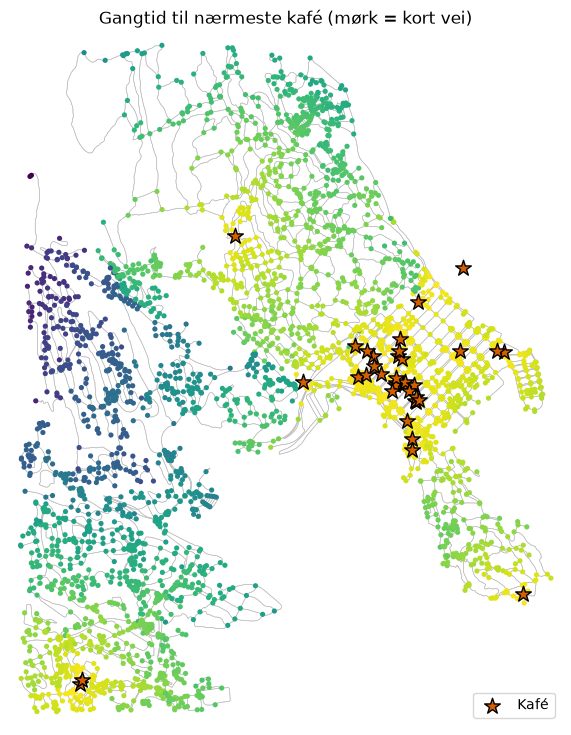

Median 11.8 min, maks 56.4 min, 29% av kryssene har kafé innen 5 min


In [22]:
KAFE_FIL = DATA / "kafeer.gpkg"
if KAFE_FIL.exists():
    kafeer = gpd.read_file(KAFE_FIL)
else:
    kafeer = med_retry(ox.features.features_from_point, SENTRUM, tags={"amenity": "cafe"}, dist=2500)
    kafeer = kafeer.assign(geometry=kafeer.representative_point())[["name", "geometry"]].reset_index(drop=True)
    kafeer.to_file(KAFE_FIL)
print(len(kafeer), "kaféer funnet")

kilder = list(set(ox.distance.nearest_nodes(G_gange, kafeer.geometry.x, kafeer.geometry.y)))
tid_til_kafe = nx.multi_source_dijkstra_path_length(G_gange, kilder, weight="travel_time")
nx.set_node_attributes(G_gange, {n: tid_til_kafe.get(n, np.nan) / 60 for n in G_gange.nodes}, "min_til_kafe")

nc = ox.plot.get_node_colors_by_attr(G_gange, "min_til_kafe", cmap="viridis_r")
fig, ax = ox.plot_graph(
    G_gange, node_color=nc, node_size=14, edge_color="#bbb", edge_linewidth=0.4,
    bgcolor="white", show=False, close=False, figsize=(9, 9),
)
ax.scatter(kafeer.geometry.x, kafeer.geometry.y, c="#D55E00", marker="*", s=140, edgecolor="k", zorder=5, label="Kafé")
ax.set_title("Gangtid til nærmeste kafé (mørk = kort vei)")
ax.legend(loc="lower right")
plt.show()

verdier = pd.Series(nx.get_node_attributes(G_gange, "min_til_kafe")).dropna()
print(f"Median {verdier.median():.1f} min, maks {verdier.max():.1f} min, "
      f"{(verdier <= 5).mean():.0%} av kryssene har kafé innen 5 min")

## Bonus B: Hvilke gater er viktigst? (edge betweenness)

*Edge betweenness* teller hvor mange korteste veier mellom tilfeldige punktpar som går gjennom hver strekning.
Høy verdi betyr kritisk gate. Vi bruker et utvalg på 300 kilder for å spare tid.

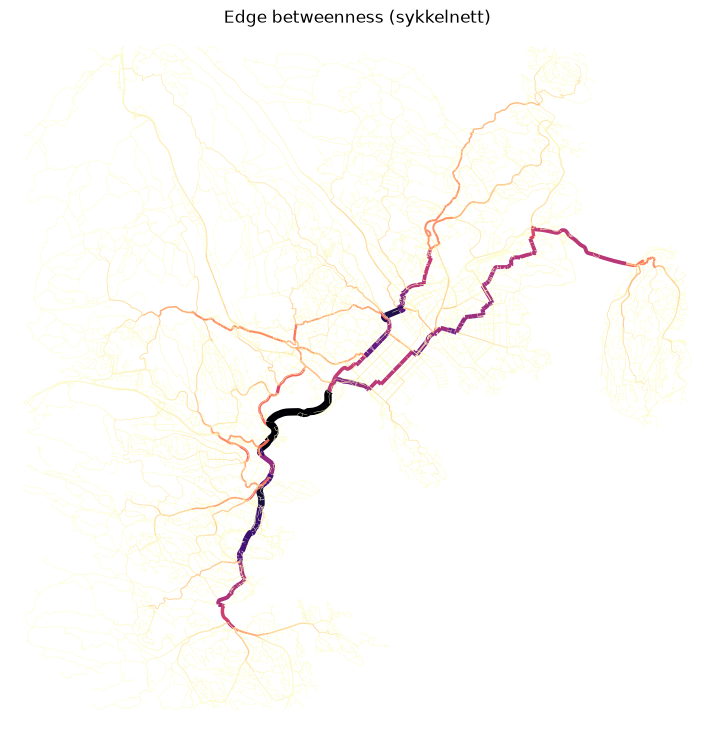

In [23]:
Gu = ox.convert.to_undirected(G_sykkel)
eb = nx.edge_betweenness_centrality(nx.Graph(Gu), k=300, weight="length", seed=42)
for u, v, d in Gu.edges(data=True):
    d["betweenness"] = eb.get((u, v), eb.get((v, u), 0.0))

ec = ox.plot.get_edge_colors_by_attr(Gu, "betweenness", cmap="magma_r")
lw = [0.3 + 5 * d["betweenness"] / max(eb.values()) for *_, d in Gu.edges(data=True)]
fig, ax = ox.plot_graph(Gu, node_size=0, edge_color=ec, edge_linewidth=lw, bgcolor="white", show=False, close=False, figsize=(9, 9))
ax.set_title("Edge betweenness (sykkelnett)")
plt.show()

## Bonus C: Gateorientering og Kvadraturen

Kristiansand er kjent for **Kvadraturen**, en planlagt rutenettby fra 1641. Det viser seg tydelig
i fordelingen av gateretninger. *Orientation entropy* er lavere jo mer ordnet rutenettet er
(rundt 3,6 for helt tilfeldige retninger).

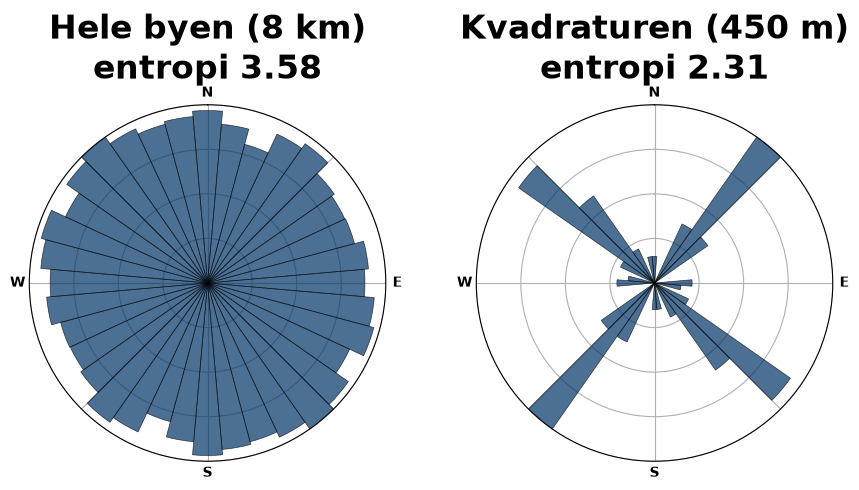

In [24]:
G_kvad = hent_nett("kvadraturen", "drive", dist=450, senter=KOORD["Domkirken"])

fig, axes = plt.subplots(1, 2, figsize=(10, 5), subplot_kw={"projection": "polar"})
for ax, (tittel, G) in zip(axes, [("Hele byen (8 km)", G_bil), ("Kvadraturen (450 m)", G_kvad)]):
    Gb = ox.bearing.add_edge_bearings(ox.convert.to_undirected(G))
    ox.plot.plot_orientation(Gb, ax=ax, title=f"{tittel}\nentropi {ox.bearing.orientation_entropy(Gb):.2f}")
plt.tight_layout()
plt.show()

## Videre

- `ox.routing.k_shortest_paths(G, a, b, k=3, weight=...)` gir alternative ruter
- `ox.elevation.add_node_elevations_raster` / `add_edge_grades` lar deg straffe bakker
  (krever en høydemodell-GeoTIFF, f.eks. fra Kartverket)
- Bytt `weight` mot en egen funksjon: `weight=lambda u, v, d: ...` i NetworkX
- Last inn egne data fra `../eksempeldata` (brannstasjoner, bygg) og koble til nettverket med `nearest_nodes`
- Last ned hele kommunen med `ox.graph_from_place("Kristiansand, Norway")` (tar lengre tid)